# Solar Filament Detection & Segmentation: Offline CPU Demo
**Solar Filament Segmentation Challenge 2026**

This notebook runs end-to-end offline inference and validation on `sample_images/` using the compact checkpoints stored directly in `weights/` and `weights/phase3/`:
1. **Device Setup**: CPU-compatible FP32 compute (`weights=None`, zero network calls).
2. **Multi-Scale CLAHE Preprocessing**: 3-channel transformation at 1536 px.
3. **Single-Model CPU Inference (`weights/r50_1536_clahe_f0.pt`)**: Fast single-pass preview (`~5 s/img`, default uncalibrated `tau_score=0.35`) across all 3 sample observations.
4. **Compact 6-Model Ensemble Verification (`configs/compact_6model_fold0.json`)**: Verifies all **42** `weights/checksums.sha256` entries (`6` Fold-0 Mask R-CNN + `36` Phase 3B files), confirms FP16 -> FP32 upcast, and executes **24-view 4-flip TTA** (`Rule B`) on `sample_images[0]`.
5. **Phase 3B Refiner & 25-Booster LightGBM Check (`weights/phase3/`)**: Runs `ResidualCropRefinerUNet` (`160x160`), `WideContextRefinerUNetV2` (`224x224`), and the 25-booster `LightGBM S27` ranker on `sample_images[0]` consensus detections (`Rule C` offline component test).
6. **Disjoint Canvas, Validation & Overlays**: Asserts $\max \sum M_i \le 1$, runs `validate_submission`, and plots prediction overlays.

In [1]:
import hashlib
import os
import sys
import time
from pathlib import Path

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch

# Normalize working directory to repository root so all paths stay relative
_cwd = Path.cwd()
if (_cwd / "scripts").is_dir() and (_cwd / "weights").is_dir():
    REPO_ROOT = _cwd
elif (_cwd.parent / "scripts").is_dir() and (_cwd.parent / "weights").is_dir():
    REPO_ROOT = _cwd.parent
else:
    REPO_ROOT = _cwd
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from scripts.common import EMPTY_RLE, extract_state_dict, preprocess_solar_image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Device: {device} (strict float32 compute, offline)")
if device.type == "cpu":
    print(f"CPU logical cores: {os.cpu_count()}")

Active Device: cpu (strict float32 compute, offline)
CPU logical cores: 16


### 1. Sample Images & Multi-Scale CLAHE Preprocessing
Full-disk H-alpha observations (`2048x2048`) exhibit limb darkening and variable chromospheric contrast. Each image is converted into 3 normalized channels:
- **Ch0**: Normalized linear grayscale
- **Ch1**: Fine CLAHE (`clipLimit=2.0`, `tileGridSize=(8, 8)`)
- **Ch2**: Coarse CLAHE (`clipLimit=4.0`, `tileGridSize=(16, 16)`)

  - sample_images/20110120105534Ch.jpeg (765.6 KB)
  - sample_images/20110130110334Ch.jpeg (693.4 KB)
  - sample_images/20110214175414Mh.jpeg (669.3 KB)


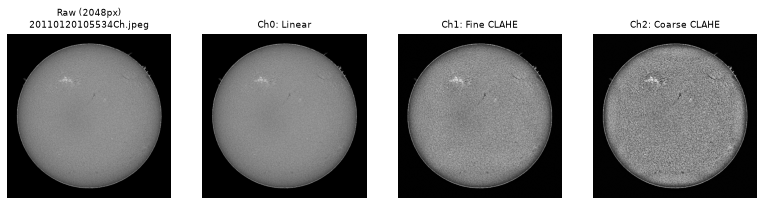

In [2]:
sample_dir = Path("sample_images")
sample_files = [
    "20110120105534Ch.jpeg",
    "20110130110334Ch.jpeg",
    "20110214175414Mh.jpeg",
]
sample_paths = [sample_dir / f for f in sample_files]
for p in sample_paths:
    assert p.is_file(), f"Missing sample image: {p}"
    print(f"  - {p.as_posix()} ({p.stat().st_size / 1024:.1f} KB)")

demo_raw = cv2.imread(str(sample_paths[0]), cv2.IMREAD_GRAYSCALE)
demo_prep = preprocess_solar_image(demo_raw, target_size=1536)

# Render downsampled 512x512 preview to keep committed notebook size compact
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), dpi=72)
axes[0].imshow(cv2.resize(demo_raw, (512, 512)), cmap="gray")
axes[0].set_title(f"Raw (2048px)\n{sample_paths[0].name}", fontsize=9)
axes[0].axis("off")

for idx, (label, ch) in enumerate([
    ("Ch0: Linear", demo_prep[0]),
    ("Ch1: Fine CLAHE", demo_prep[1]),
    ("Ch2: Coarse CLAHE", demo_prep[2]),
], start=1):
    axes[idx].imshow(cv2.resize(ch, (512, 512)), cmap="gray")
    axes[idx].set_title(label, fontsize=9)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

### 2. Offline Inference from `weights/` (`r50_1536_clahe_f0.pt`)
Loads `weights/r50_1536_clahe_f0.pt` via relative path, upcasts FP16 parameters to FP32, and executes inference in FP32 without `bfloat16` autocast across all 3 sample observations.

In [3]:
from scripts.run_pipeline import run_pipeline

output_csv = Path("work/demo_predictions.csv")
df_predictions, results = run_pipeline(
    input_dir=sample_dir,
    output_csv=output_csv,
    mode="single",
    weights_dir=Path("weights"),
    checkpoint="weights/r50_1536_clahe_f0.pt",
    device=device,
    tta=False,
    validate=False,
)

runtimes = [r["elapsed_s"] for r in results.values()]
print(f"\nPer-image runtimes: {[round(t, 2) for t in runtimes]} s | Mean: {np.mean(runtimes):.2f} s/img")


  Solar Filament Inference Pipeline
  Mode:           SINGLE
  Decision Rule:  threshold
  Device:         cpu (float32 compute)
  Images to Run:  3 from sample_images
  TTA Enabled:    False (1 view per model)

Locating model checkpoint in weights...
Using checkpoint: weights/r50_1536_clahe_f0.pt


Model ready (img_size=1536, anchors5=False). Running inference...


  [001/003] 20110120105534Ch: 5 filaments (4.75s)


  [002/003] 20110130110334Ch: 3 filaments (4.83s)


  [003/003] 20110214175414Mh: 4 filaments (5.21s)

Saved 12 prediction rows to: work/demo_predictions.csv

Pipeline finished in 15.5s (5.15s/img).

Per-image runtimes: [4.75, 4.83, 5.21] s | Mean: 4.93 s/img


### 3. Compact 6-Model Fold-0 Ensemble Check (`weights/` & `configs/compact_6model_fold0.json`, 24-View 4-Flip TTA)
Verifies SHA-256 checksums for all **42** in-repo files in `weights/` & `weights/phase3/` (`< 100 MB` each), asserts FP16 -> FP32 upcasting in `extract_state_dict`, and runs the compact 6-family ensemble with **4-flip TTA (`24` views total)** under calibrated `Rule B` (`tau_score=0.75, tau_mask=0.55, gamma=1.5`) on `sample_images[0]`.

- **Why `limit=1` on CPU**: Full 24-view TTA across the `1536`/`1792`/`2048` px models runs in `~130 s/img` on 16 CPU cores (`131.3 s/img`, `393.97 s` total across all 3 sample images in `audit/final_release_analyses.json`).
- **Expected Count (`2` vs Single-Model `5`)**: Single-model `--no_tta` uses loose `tau_score=0.35` (`5` detections on `sample_images[0]`, two with scores `< 0.50`). Under calibrated multi-view `Rule B` (`tau_score=0.75`), both this 24-view Compact 6-Model Fold-0 ensemble and the authoritative 30-model Submissions A & B filter out low-consensus detections and predict **`2` filaments** on `20110120105534Ch` (`6` total across all 3 sample images).

In [4]:
from scripts.regenerate_submission import check_ensemble_weights_available, load_ensemble_config

weights_dir = Path("weights")
checksum_lines = [l.strip().split(None, 1) for l in (weights_dir / "checksums.sha256").read_text().splitlines() if l.strip()]
for expected_sha, fname in checksum_lines:
    fpath = weights_dir / fname
    actual_sha = hashlib.sha256(fpath.read_bytes()).hexdigest()
    assert actual_sha == expected_sha, f"Checksum mismatch on {fname}"
    size_mb = fpath.stat().st_size / (1024 * 1024)
    assert size_mb < 100.0, f"{fname} exceeds 100 MB ({size_mb:.2f} MB)"

# Verify FP16 -> FP32 upcast on one checkpoint
sample_sd = extract_state_dict(torch.load(weights_dir / "r50_2048_f0.pt", map_location="cpu", weights_only=False))
first_float_dtype = next(v.dtype for v in sample_sd.values() if isinstance(v, torch.Tensor) and v.is_floating_point())
assert first_float_dtype == torch.float32, f"Expected float32 after upcast, got {first_float_dtype}"
print(f"Verified {len(checksum_lines)} checkpoints in weights/ (<100 MB each, SHA-256 OK, upcast dtype={first_float_dtype}).")

compact_cfg_path = Path("configs/compact_6model_fold0.json")
weights_ok, missing = check_ensemble_weights_available(compact_cfg_path, weights_dir=weights_dir)
assert weights_ok, f"Missing compact weights: {missing}"

output_ens_csv = Path("work/demo_compact6_predictions.csv")
df_ens, results_ens = run_pipeline(
    input_dir=sample_dir,
    output_csv=output_ens_csv,
    mode="ensemble",
    rule="B",
    config_path=compact_cfg_path,
    weights_dir=weights_dir,
    device=device,
    tta=True,
    limit=1,
    validate=False,
)
ens_t = next(iter(results_ens.values()))["elapsed_s"]
ens_n = int((df_ens["segmentation_rle"] != EMPTY_RLE).sum())
print(f"Compact 6-model Fold-0 (24-view 4-flip TTA, Rule B) on sample[0]: {ens_n} filaments in {ens_t:.2f} s")

Verified 42 checkpoints in weights/ (<100 MB each, SHA-256 OK, upcast dtype=torch.float32).

  Solar Filament Inference Pipeline
  Mode:           ENSEMBLE
  Decision Rule:  threshold
  Device:         cpu (float32 compute)
  Images to Run:  1 from sample_images
  TTA Enabled:    True (4 views per model)

Loading ensemble (compact_6model_fold0) with 6 models from weights...


  Loaded f0_1536      (clahe, 1536px) from r50_1536_clahe_f0.pt


  Loaded f0_anchors5  (anchors5, 1536px) from r50_1536_anchors5_f0.pt


  Loaded f0_dice      (dice, 1536px) from r50_1536_dice_f0.pt


  Loaded f0_2048      (2048, 2048px) from r50_2048_f0.pt


  Loaded f0_a5dice    (a5dice, 1536px) from r50_1536_a5dice_f0.pt


  Loaded f0_1792      (1792_clahe, 1792px) from r50_1792_clahe_f0.pt

Executing 6-model 24-view Flip TTA WMF inference...


  [001/001] 20110120105534Ch: 2 filaments (133.69s)

Saved 2 prediction rows to: work/demo_compact6_predictions.csv

Pipeline finished in 136.0s (135.98s/img).
Compact 6-model Fold-0 (24-view 4-flip TTA, Rule B) on sample[0]: 2 filaments in 133.69 s


### 3B. Phase 3B Refiner & 25-Booster LightGBM Check (`weights/phase3/`, Rule C Offline Smoke)
Loads `configs/phase3b_refiner.json`, both Fold-0 FP16 boundary refiners (`ResidualCropRefinerUNet` `160x160` and `WideContextRefinerUNetV2` `224x224`), and all `25` cross-fitted `LightGBM` boosters from `weights/phase3/` in strict `float32`, verifying feature extraction, 4-TTA crop refinement, and pixel-disjoint RLE synthesis on `sample_images[0]` consensus detections (note: full 180-image `--rule C` also loads the external full-disk `ResNet50`/`ResNeXt101` semantic U-Nets via `scripts/download_weights.sh --family refiner`).

In [5]:
import json
from pycocotools import mask as mu
from scripts.refiner_pipeline import (
    FRAME_SIZE,
    ResidualCropRefinerUNet,
    WideContextRefinerUNetV2,
    extract_crop_refiner_inputs,
    extract_wide_refiner_inputs,
    load_lgb_boosters,
    materialize_disjoint_rows_phase3b,
    predict_4tta_crop_v1,
    predict_4tta_wide_v2,
)

t_p3 = time.time()
p3_cfg = json.loads(Path("configs/phase3b_refiner.json").read_text())
p3_tau = float(p3_cfg["ranker"]["tau_score"])
boosters, feat_names = load_lgb_boosters(weights_dir=Path("weights"))
assert len(boosters) == 25 and len(feat_names) == 27

stem0 = next(iter(results_ens.keys()))
img0 = results_ens[stem0]["img_gray"]
cands_p3 = []
for r in results_ens[stem0]["rows"]:
    if r["segmentation_rle"] == EMPTY_RLE:
        continue
    m = mu.decode({"size": [FRAME_SIZE, FRAME_SIZE], "counts": r["segmentation_rle"].encode("ascii")}) > 0
    ys, xs = np.where(m)
    x1, y1, x2, y2 = int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1
    ux1, uy1 = max(0, x1 - 12), max(0, y1 - 12)
    ux2, uy2 = min(FRAME_SIZE, x2 + 12), min(FRAME_SIZE, y2 + 12)
    wx1, wy1 = max(0, x1 - 56), max(0, y1 - 56)
    wx2, wy2 = min(FRAME_SIZE, x2 + 56), min(FRAME_SIZE, y2 + 56)
    b55 = m[y1:y2, x1:x2]
    cands_p3.append({
        "box": np.array([x1, y1, x2, y2], dtype=np.int32),
        "binary_55": b55,
        "prob_crop": (b55.astype(np.float32) * 0.85).astype(np.float16),
        "u_box": np.array([ux1, uy1, ux2, uy2], dtype=np.int32),
        "w_box": np.array([wx1, wy1, wx2, wy2], dtype=np.int32),
        "u_prob": m[uy1:uy2, ux1:ux2].astype(np.float16),
        "orig_area": int(b55.sum()),
        "rule_b_score": 0.90,
        "lgb_score": 0.50,
    })

if cands_p3:
    r50_zero = np.zeros((2, FRAME_SIZE, FRAME_SIZE), dtype=np.float32)
    rnx_zero = np.zeros((3, FRAME_SIZE, FRAME_SIZE), dtype=np.float32)
    vx1, vs1 = extract_crop_refiner_inputs(cands_p3, img0)
    vx2, vs2, _ = extract_wide_refiner_inputs(cands_p3, img0, r50_zero, rnx_zero)

    m1 = ResidualCropRefinerUNet(in_ch=6, base=32)
    m1.load_state_dict(extract_state_dict(torch.load("weights/phase3/crop_refiner_f0_fp16.pt", map_location="cpu", weights_only=False)))
    m1.float().to(device).eval()
    v1_m, v1_i = predict_4tta_crop_v1(m1, vx1, vs1, device)

    m2 = WideContextRefinerUNetV2(in_ch=11, base=40)
    m2.load_state_dict(extract_state_dict(torch.load("weights/phase3/wide_refiner_v2_f0_fp16.pt", map_location="cpu", weights_only=False)))
    m2.float().to(device).eval()
    v2_m, v2_i = predict_4tta_wide_v2(m2, vx2, vs2, device)

    for idx_c, c in enumerate(cands_p3):
        ux1, uy1, ux2, uy2 = c["u_box"]
        wx1, wy1, wx2, wy2 = c["w_box"]
        c["cnn_u_prob"] = cv2.resize(v1_m[idx_c], (ux2 - ux1, uy2 - uy1), interpolation=cv2.INTER_LINEAR).astype(np.float16)
        c["wref_prob"] = cv2.resize(v2_m[idx_c], (wx2 - wx1, wy2 - wy1), interpolation=cv2.INTER_LINEAR).astype(np.float16)
        c["unet_u_prob"] = np.zeros((uy2 - uy1, ux2 - ux1), dtype=np.float16)

    X_dummy = np.zeros((len(cands_p3), len(feat_names)), dtype=np.float32)
    lgb_smoke = float(np.mean([b.predict(X_dummy)[0] for b in boosters]))
    df_p3_smoke, p3_stats = materialize_disjoint_rows_phase3b([stem0], {stem0: cands_p3}, tau=p3_tau)
    p3_masks = [
        mu.decode({"size": [FRAME_SIZE, FRAME_SIZE], "counts": rle.encode("ascii")}) > 0
        for rle in df_p3_smoke["segmentation_rle"] if rle != EMPTY_RLE
    ]
    p3_ov = int(np.stack(p3_masks, axis=0).sum(axis=0).max()) if p3_masks else 0
    assert p3_ov <= 1, f"Phase 3B smoke overlap: {p3_ov}"
    print(
        f"Phase 3B offline smoke on {stem0}: {len(cands_p3)} cands refined "
        f"(V1 IoU_head={v1_i.mean():.3f}, V2 IoU_head={v2_i.mean():.3f}, 25x LGB={lgb_smoke:.4f}) -> "
        f"{p3_stats['total_filaments']} disjoint filaments (max_overlap={p3_ov}) in {time.time() - t_p3:.2f}s"
    )

Phase 3B offline smoke on 20110120105534Ch: 2 cands refined (V1 IoU_head=0.746, V2 IoU_head=0.698, 25x LGB=0.1058) -> 2 disjoint filaments (max_overlap=1) in 1.03s


### 4. Disjoint Canvas & Submission Schema Verification
Asserts $\max_{(x,y)} \sum_i M_i(x,y) \le 1$ across predicted instances and validates `work/demo_predictions.csv` using `scripts/validate_submission.py`.

In [6]:
from pycocotools import mask as mu
from scripts.validate_submission import validate_submission

def _extract_masks(res):
    if "masks" in res:
        return res["masks"]
    masks = []
    for r in res.get("rows", []):
        if r["segmentation_rle"] != EMPTY_RLE:
            masks.append(mu.decode({"size": [2048, 2048], "counts": r["segmentation_rle"].encode("ascii")}).astype(bool))
    return masks

for tag, res_map in [("Single-Model", results), ("Compact-6-Model", results_ens)]:
    for stem, res in res_map.items():
        masks = _extract_masks(res)
        if len(masks) > 0:
            stack = np.stack(masks, axis=0)
            max_overlap = int(stack.sum(axis=0).max())
            total_px = int(stack.sum())
            assert max_overlap <= 1, f"Overlap detected in {tag} / {stem}: max_overlap={max_overlap}"
            print(f"[{tag}] {stem}: {len(masks)} filaments, {total_px:,} px, max_overlap={max_overlap} (DISJOINT)")
        else:
            print(f"[{tag}] {stem}: 0 filaments (DISJOINT)")

report = validate_submission(str(output_csv), str(sample_dir), expected_count=len(sample_paths))
assert report["all_passed"], f"Validation errors: {report['errors']}"
print(f"\n[VALIDATION PASSED] {report['total_rows']} rows across {report['unique_images']} sample images.")

[Single-Model] 20110120105534Ch: 5 filaments, 4,683 px, max_overlap=1 (DISJOINT)
[Single-Model] 20110130110334Ch: 3 filaments, 7,170 px, max_overlap=1 (DISJOINT)
[Single-Model] 20110214175414Mh: 4 filaments, 4,344 px, max_overlap=1 (DISJOINT)
[Compact-6-Model] 20110120105534Ch: 2 filaments, 2,680 px, max_overlap=1 (DISJOINT)

[VALIDATION PASSED] 12 rows across 3 sample images.


### 5. Prediction Overlays & Submission Preview
Shows predicted disjoint filament masks and confidence scores on all 3 `sample_images/` observations (downsampled preview for compact notebook storage).

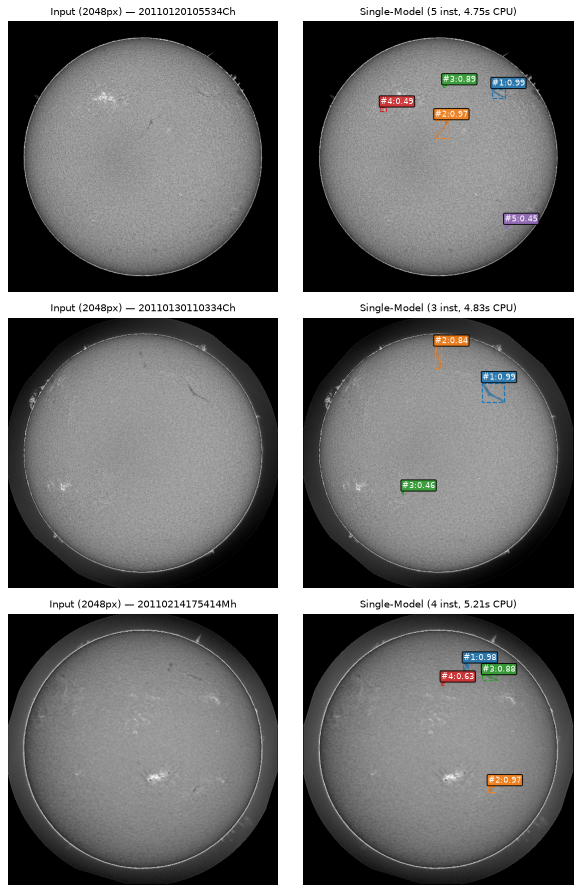

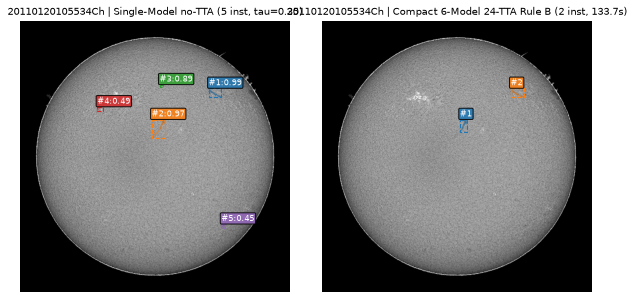

In [7]:
cmap = plt.get_cmap("tab10")
disp_sz = 512

def _draw_overlay(ax, img_gray, masks, scores, title):
    img_small = cv2.resize(img_gray, (disp_sz, disp_sz))
    ax.imshow(img_small, cmap="gray", vmin=20, vmax=220)
    overlay = np.zeros((disp_sz, disp_sz, 4), dtype=np.float32)
    for k, m in enumerate(masks):
        color = cmap(k % 10)
        m_small = cv2.resize(m.astype(np.uint8), (disp_sz, disp_sz), interpolation=cv2.INTER_NEAREST)
        overlay[m_small > 0] = [color[0], color[1], color[2], 0.55]
        ys, xs = np.where(m_small > 0)
        if len(ys) > 0:
            x1, y1, x2, y2 = xs.min(), ys.min(), xs.max(), ys.max()
            ax.add_patch(
                patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.1, edgecolor=color[:3], facecolor="none", linestyle="--")
            )
            lbl = f"#{k+1}:{scores[k]:.2f}" if scores is not None and k < len(scores) else f"#{k+1}"
            ax.text(x1, max(0, y1 - 6), lbl, color="white", fontsize=7.5,
                    bbox=dict(boxstyle="round,pad=0.15", facecolor=color[:3], alpha=0.85))
    ax.imshow(overlay)
    ax.set_title(title, fontsize=9.5)
    ax.axis("off")

# 1) Single-Model Overlays across all 3 sample_images/
fig, axes = plt.subplots(len(results), 2, figsize=(8.2, 4.0 * len(results)), dpi=75)
if len(results) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, (stem, res) in enumerate(results.items()):
    img_small = cv2.resize(res["img_gray"], (disp_sz, disp_sz))
    axes[row_idx, 0].imshow(img_small, cmap="gray", vmin=20, vmax=220)
    axes[row_idx, 0].set_title(f"Input (2048px) — {stem}", fontsize=9.5)
    axes[row_idx, 0].axis("off")
    _draw_overlay(
        axes[row_idx, 1],
        res["img_gray"],
        res["masks"],
        res["scores"],
        f"Single-Model ({len(res['masks'])} inst, {res['elapsed_s']:.2f}s CPU)",
    )

plt.tight_layout()
plt.show()

# 2) Side-by-side comparison on sample_images[0]: Single-Model vs Compact 6-Model (24-view TTA)
first_stem = next(iter(results_ens.keys()))
res_single0 = results[first_stem]
res_ens0 = results_ens[first_stem]
ens0_masks = _extract_masks(res_ens0)

fig2, axes2 = plt.subplots(1, 2, figsize=(8.2, 4.0), dpi=75)
_draw_overlay(
    axes2[0],
    res_single0["img_gray"],
    res_single0["masks"],
    res_single0["scores"],
    f"{first_stem} | Single-Model no-TTA ({len(res_single0['masks'])} inst, tau=0.35)",
)
_draw_overlay(
    axes2[1],
    res_ens0["img_gray"],
    ens0_masks,
    None,
    f"{first_stem} | Compact 6-Model 24-TTA Rule B ({len(ens0_masks)} inst, {res_ens0['elapsed_s']:.1f}s)",
)
plt.tight_layout()
plt.show()

In [8]:
df_preview = df_predictions.copy()
df_preview["segmentation_rle"] = df_preview["segmentation_rle"].apply(lambda s: s[:28] + "..." if len(s) > 28 else s)
print(df_preview.to_string(index=False))

       filament_id                segmentation_rle
20110120105534Ch_1 k_Ri22no12N1O2N1O2O000gPNJgn...
20110120105534Ch_2 ^kVn14ko11O1N2O0O2O1O001N101...
20110120105534Ch_3 ^_nQ22mo12N2O1N2O0O1O10O0000...
20110120105534Ch_4 TeZT14ho15M2O00001O0000O100O...
20110120105534Ch_5 ]`Wo27go14M2M4L3O3L2O1O1O0O0...
20110130110334Ch_1 `_fd22jo18L3M3N1N2O1O1O101O0...
20110130110334Ch_2 SXTn1d0Yo14L4L4L4L4K6K5K5K5J...
20110130110334Ch_3 aYe^17go12@`0O1O010001O3L7I3...
20110214175414Mh_1 T]h[2=`o14L4M3M2O2mNWOmRNj0Q...
20110214175414Mh_2 fY]g27go16L3L2O1N100O1O1O0O0...
20110214175414Mh_3 ^^hd24lo11N2O1O1O1O001N10O10...
20110214175414Mh_4 a`TQ28eo14H8N100O2O000000000...


### Reproduction Notes
- **In-Repo Demo (`weights/` + `weights/phase3/`, 42 verified files, 583 MB total)**: Verifies Stage-1 detection/WMF, Phase 3B `CropRefinerV1` + `WideRefinerV2` + 25-booster LightGBM offline CPU execution, disjointness, and validation without downloading external archives.
- **Exact Challenge Submission Reproduction (`Rule C` Winner & Rules A/B)**: Download all 7 archives from GitHub Releases (`Harru230/solar`) into `work/checkpoints/` and execute:
  ```bash
  bash scripts/download_weights.sh --all --tag v1.0.0 --repo Harru230/solar
  python scripts/regenerate_submission.py --rule C --mode full --config configs/phase3b_refiner.json --validate
  python scripts/regenerate_submission.py --rule A --mode full --config configs/final_ensemble.json --validate
  python scripts/regenerate_submission.py --rule B --mode full --config configs/final_ensemble.json --validate
  ```